simplified figure for EGU presentation

In [1]:
# Standard imports
import pathlib
from itertools import product

# Third party imports
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Internal imports

In [2]:
# set plot style
%matplotlib widget
plt.style.use('plot_style.txt')

# output path for figures 
output_path = pathlib.Path("/home/jonas/shared/Work/SSeep2026/Figures")

In [3]:
config = ['large', 'medium', 'small']
aq_para = ['vGM', 'BCB']
texture = ['SAND', 'SAND_LOAM']

data = {}
for v1, v2, v3 in product(config, aq_para, texture):
    df = pd.read_csv(f'../data/exp4_{v1}_{v2}_{v3}/rel_error.csv', index_col=0)

    idx1 = np.logical_and(df['unsaturated'], df['clogged'])
    idx2 = np.logical_and(~df['van_cap_zone'], df['increasing'])
    idx = np.logical_and(idx1, idx2)
    df = df.loc[idx]

    data[v1, v2, v3, 'mf'] = df['rel_err_mf'].values
    data[v1, v2, v3, 'dis'] = df['rel_err_dis'].values
    data[v1, v2, v3, 'max'] = df['rel_err_max'].values

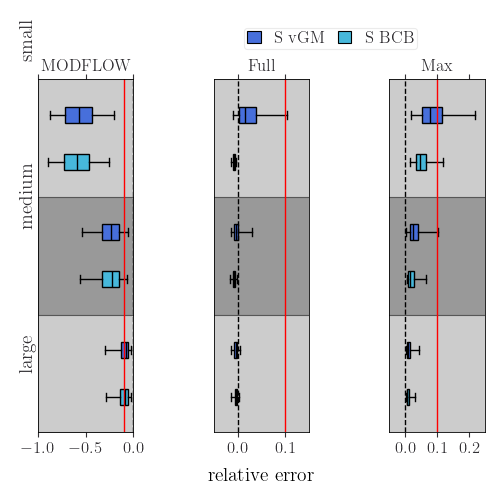

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(5, 5))


y = np.array([1, 2.5, 4])
dy = 0.75

c_S_vGM = "#476fdbff"
c_S_BCB = "#47b8dbff"

# MODFLOW
_data = [data[v1, 'vGM', 'SAND', 'mf'] for v1 in config]
bp = axs[0].boxplot(_data, positions=y + 1.4 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_S_vGM)

_data = [data[v1, 'BCB', 'SAND', 'mf'] for v1 in config]
bp = axs[0].boxplot(_data, positions=y + 0.6 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_S_BCB)

# fully disconnected
_data = [data[v1, 'vGM', 'SAND', 'dis'] for v1 in config]
bp = axs[1].boxplot(_data, positions=y + 1.4 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_S_vGM)

_data = [data[v1, 'BCB', 'SAND', 'dis'] for v1 in config]
bp = axs[1].boxplot(_data, positions=y + 0.6 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_S_BCB)

# maximal rel. error
_data = [data[v1, 'vGM', 'SAND', 'max'] for v1 in config]
bp = axs[2].boxplot(_data, positions=y + 1.4 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_S_vGM)

_data = [data[v1, 'BCB', 'SAND', 'max'] for v1 in config]
bp = axs[2].boxplot(_data, positions=y + 0.6 * dy, whis=(2.2, 97.8), widths=0.2, patch_artist=True,
            orientation='horizontal', sym='', medianprops={'c':'k'})
for patch in bp['boxes']:
    patch.set_facecolor(c_S_BCB)

for ax in axs:
    ax.axvline(0, ls='--', c='k', lw=1)
    ax.fill_between([-1, 1], y1=[1, 1], y2=[2.5, 2.5], color='k', alpha=0.2, zorder=0)
    ax.fill_between([-1, 1], y1=[2.5, 2.5], y2=[4, 4], color='k', alpha=0.4, zorder=0)
    ax.fill_between([-1, 1], y1=[4, 4], y2=[5.5, 5.5], color='k', alpha=0.2, zorder=0)
axs[0].axvline(-0.1, ls='-', c='r', lw=1)
axs[1].axvline(0.1, ls='-', c='r', lw=1)
axs[2].axvline(0.1, ls='-', c='r', lw=1)

for ax in axs:
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.tick_params(top=True, right=True)
    ax.set(xscale='linear', yscale='linear')
    ax.minorticks_off()
    ax.set_yticks([], labels=[])
    ax.set_ylim(ymin=1, ymax=5.5)

axs[1].set_xlabel('relative error', labelpad=8)
axs[0].set_xlim(xmin=-1, xmax=0)
axs[0].set_xticks([-1, -0.5, 0])
axs[1].set_xlim(xmin=-0.05, xmax=0.15)
axs[1].set_xticks([0, 0.1])
axs[2].set_xlim(xmin=-0.05, xmax=0.25)
axs[2].set_xticks([0, 0.1, 0.2])

axs[0].set_title('MODFLOW', loc='center', fontsize=12)
axs[1].set_title('Full', loc='center', fontsize=12)
axs[2].set_title('Max', loc='center', fontsize=12)

axs[0].text(-1.2, 6, 'small', rotation='vertical', va='center', fontsize=14)
axs[0].text(-1.2, 4, 'medium', rotation='vertical', va='center', fontsize=14)
axs[0].text(-1.2, 2, 'large', rotation='vertical', va='center', fontsize=14)


labels = [Patch(facecolor=c_S_vGM, edgecolor='k', label='S vGM'),
          Patch(facecolor=c_S_BCB, edgecolor='k', label='S BCB')]

plt.legend(handles=labels,fontsize=12, handlelength=0.8, ncols=4,
           columnspacing=0.8, bbox_transform=axs[1].transAxes,
           bbox_to_anchor=(2.22, 1.17)
)
plt.tight_layout()
#plt.savefig(output_path / 'rel_error_EGU.pdf')